# Energy-Based Model on CelebA Dataset

In [1]:
import torch
from torch import nn

## Download the CelebA Dataset

In [2]:
# Download the celebA dataset 
import torchvision
from torchvision import transforms
from torch.utils.data import DataLoader

# Create a set of transforms to apply to the images
# a. Convert the images to PyTorch tensors
# b. Resize the images to 128x128
# c. Normalize the image pixel values to [-1, 1]
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Resize((128, 128)),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

# Download the celebA dataset
train_dataset = torchvision.datasets.CelebA(
    root='../../data',
    split='train',
    target_type='attr',
    transform=transform,
    download=False
)

test_dataset = torchvision.datasets.CelebA(
    root='../../data',
    split='test',
    target_type='attr',
    transform=transform,
    download=False
)

# Get a sample image to determine the image shape
sample_img, _ = train_dataset[0]

# Create a DataLoader to load the dataset in batches
BATCH_SIZE = 128
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

In [3]:
# Print the number of samples in the training and test datasets
print(f'Number of training samples: {len(train_dataset)}')
print(f'Number of test samples: {len(test_dataset)}')

# Print sample shapes from the training and test datasets
print(f'Sample training image shape: {train_dataset[0][0].shape}')
print(f'Sample test image shape: {test_dataset[0][0].shape}')

Number of training samples: 162770
Number of test samples: 19962
Sample training image shape: torch.Size([3, 128, 128])
Sample test image shape: torch.Size([3, 128, 128])


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0000001].


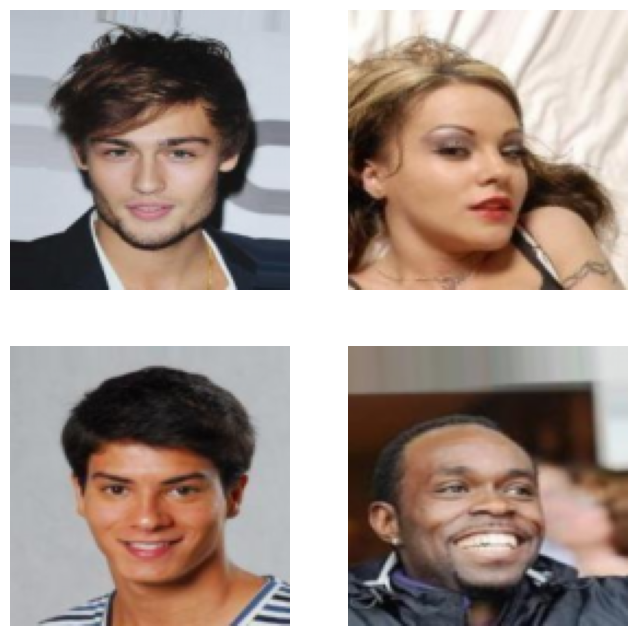

In [4]:
## Visualize some images from the dataset
import matplotlib.pyplot as plt
import numpy as np

for images, labels in train_loader:
    # Plot a few images to verify the transformations
    plt.figure(figsize=(8,8))
    for i in range(4):
        plt.subplot(2, 2, i+1)
        # Print shape of the image tensor
        # print(images[i].shape)
        # Convert back to [0, 1] for display
        plt.imshow(np.transpose(((images[i] + 1) / 2).numpy(), (1, 2, 0)))
        # Min and max values in image tensor
        # print(torch.min(images[i]), torch.max(images[i]))
        # plt.title(f'Attributes: {labels[i].numpy()}')
        plt.axis('off')
    plt.show()
    break 

In [5]:
# Create the Energy-Based Model and move it to the appropriate device
from energy_function import EnergyFunction

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

energy_function = EnergyFunction().to(device)
energy_function.train()

EnergyFunction(
  (conv_layers): Sequential(
    (0): Conv2d(3, 16, kernel_size=(5, 5), stride=(2, 2), padding=(2, 2))
    (1): Swish()
    (2): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): Swish()
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (5): Swish()
    (6): Conv2d(64, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (7): Swish()
    (8): Conv2d(64, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (9): Swish()
  )
  (linear_layers): Sequential(
    (0): Linear(in_features=1024, out_features=128, bias=True)
    (1): Swish()
    (2): Linear(in_features=128, out_features=1, bias=True)
  )
)

In [6]:
## Create the sampler
import sys
from pathlib import Path

# The notebook runs from EBM/EBM_celebA; add EBM to import its sibling package.
ebm_dir = str(Path.cwd().parent)
if ebm_dir not in sys.path:
    sys.path.insert(0, ebm_dir)

from EBM_MNIST.sampler import LangevinSampler

sampler = LangevinSampler(energy_function=energy_function, img_shape=sample_img.shape, batch_size=BATCH_SIZE)

### Training the Energy-Based Model on the celebA dataset

In [14]:
import torch.nn.functional as F
from tqdm.auto import tqdm
import wandb
import os

CHECKPOINT_DIR = "./checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

## Params: 
NUM_EPOCHS = 10
REG_LAMBDA = 0.1  # Weight for regularization loss
N_STEPS = 80  # Number of Langevin steps for sampling


CHECKPOINT_NAME = f"ebm_lambda_{REG_LAMBDA}_ep_{NUM_EPOCHS}_steps_{N_STEPS}.pt"

## Start a new wandb run to track this script.
run = wandb.init(
    # Set the wandb entity where your project will be logged (generally your team name).
    entity="mechtrics7-task-proxemics",
    # Set the wandb project where this run will be logged.
    project="modeling_generation",
    # Run name for this experiment
    name=f"ebm_lambda_{REG_LAMBDA}_ep_{NUM_EPOCHS}_steps_{N_STEPS}",
    # Track hyperparameters and run metadata.
    config={
        "num_epochs": NUM_EPOCHS,
        "lambda": REG_LAMBDA,
        "n_steps": N_STEPS
        
    }
)

# Initialize the optimizer
optimizer = torch.optim.Adam(energy_function.parameters(), lr=5e-4)

for epoch in range(NUM_EPOCHS):
    train_loss = 0
    progress = tqdm(train_loader, desc=f'Epoch {epoch+1}/{NUM_EPOCHS}', unit='batch')
    for batch_idx, (real_images, _) in enumerate(progress):
        # Move input images to the device
        real_images = real_images.to(device)
        batch_size = real_images.size(0)

        # Generate negative samples using Langevin dynamics
        fake_imgs = sampler.sample_new_exmps(steps=N_STEPS, step_size=10)

        # Compute the energy of the real images and the fake images
        energy_real = energy_function(real_images)
        energy_fake = energy_function(fake_imgs)

        # Compute the Contrastive Divergence loss: 
        # The difference between the energy of real and fake images
        cdiv_loss = energy_real.mean() - energy_fake.mean()

        # Compute the regularization loss for the EBM
        reg_loss = REG_LAMBDA * (energy_real.pow(2).mean() + energy_fake.pow(2).mean())

        # Total EBM loss
        ebm_loss = cdiv_loss + reg_loss

        # Zero the gradients of the optimizer, backpropagate the loss, and update the parameters
        optimizer.zero_grad()
        ebm_loss.backward()
        optimizer.step()


        train_loss += ebm_loss.item()
        progress.set_postfix(loss=f'{train_loss / (batch_idx + 1):.4f}')

        # Log the batch loss, contrastive divergence loss, and regularization loss to W&B
        run.log({
            "batch_loss": ebm_loss.item(),
            "cdiv_loss": cdiv_loss.item(),
            "reg_loss": reg_loss.item()
        })


    print(f'Epoch {epoch+1}, Loss: {train_loss / len(train_loader)}')
    run.log({"epoch": epoch+1, "loss": train_loss / len(train_loader)})

# Save the trained model checkpoint locally
torch.save(energy_function.state_dict(), os.path.join(CHECKPOINT_DIR, CHECKPOINT_NAME))

# Save the trained model checkpoint to the W&B run as an artifact
artifact = wandb.Artifact("ebm_checkpoint", type="model")
artifact.add_file(os.path.join(CHECKPOINT_DIR, CHECKPOINT_NAME))
run.log_artifact(artifact)

# Finish the W&B run
run.finish()

Epoch 1/10: 100%|██████████| 1272/1272 [07:17<00:00,  2.91batch/s, loss=-4.9874]


Epoch 1, Loss: -4.987351407794832


Epoch 2/10: 100%|██████████| 1272/1272 [07:20<00:00,  2.88batch/s, loss=-5.0000]


Epoch 2, Loss: -4.999956706409934


Epoch 3/10: 100%|██████████| 1272/1272 [07:13<00:00,  2.93batch/s, loss=-5.0000]


Epoch 3, Loss: -4.999982502475475


... (11 outputs left out)

Epoch 9, Loss: -4.999993980305749


Epoch 10/10: 100%|██████████| 1272/1272 [07:10<00:00,  2.95batch/s, loss=-5.0000]


Epoch 10, Loss: -4.999984666611414


batch_loss,█▆▄▃▃▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▂▁▄▁▁▁▂▂▁▂▁▁▂▁▂▁▁▂▁▂
cdiv_loss,▅▄▅▅▅▅▅▅▅▅▅▅▅▅▅▅▄▆▅▆▅▅▄▅▅▅▅▅▆▁▅█▅▅▅▅▅▅▅▅
epoch,▁▂▃▃▄▅▆▆▇█
loss,█▁▁▁▁▁▁▁▁▁
reg_loss,▄█▆▁▆▂▅▅▄▄▄▅▄▅▅▆▄▅▄▄▃▆▂▅▁▅▅█▄▄▅▄▄▅▅▅▄▄▄▄
batch_loss,-4.99999
cdiv_loss,-10.0118
epoch,10
loss,-4.99998
reg_loss,5.01181


## Evaluation

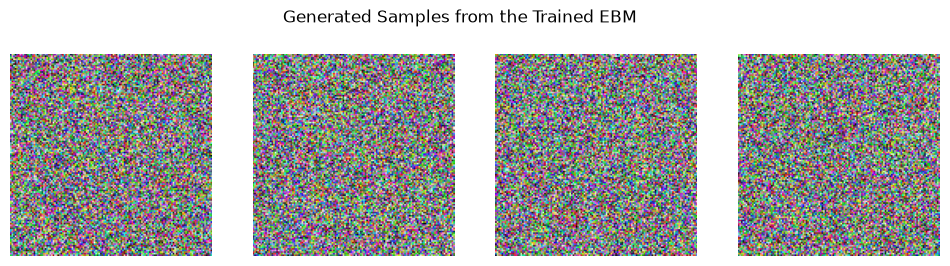

In [18]:
## Sampling and Generating New Images

# Set the energy function to evaluation mode
energy_function.eval()

# First create a few random noise images to initialize the sampling process, 
# then run the sampler for a number of steps to get new samples from the model.
eval_batch_size = 128
noise_imgs = torch.rand((eval_batch_size,) + sample_img.shape, device=device) * 2 - 1  # Random noise in [-1, 1]

# Get some samples from the eval dataset and add noise to them, then run the sampler starting from these noisy real images. This can sometimes lead to better samples than starting from pure noise.
# real_eval_imgs, _ = next(iter(test_loader))
# real_eval_imgs = real_eval_imgs[0:eval_batch_size].to(device)
# noise_imgs = real_eval_imgs + (torch.rand_like(real_eval_imgs) * 1.5 - 0.25)  # Add some noise to the real images

with torch.no_grad():
    generated_samples = LangevinSampler.generate_samples(energy_function, noise_imgs, steps=200, step_size=10)

# Visualize the generated samples from the trained EBM (RGB images)
generated_samples = generated_samples.detach().cpu().numpy()  # Move to CPU and convert to numpy for plotting
generated_samples = (generated_samples + 1) / 2  # Scale back to [0, 1] for visualization
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for i in range(4):
    axes[i].imshow(np.transpose(generated_samples[i], (1, 2, 0)))  # Show RGB image
    axes[i].axis('off')
plt.suptitle('Generated Samples from the Trained EBM')
plt.show()


### Latent Space Interpolation

- Select two random images from the dataset and encode them into the latent space.
- Interpolate between their latent vectors and decode the interpolated vectors to visualize the transition.

In [ ]:
## Latent Space Interpolation

import matplotlib.pyplot as plt
import torch

vae.eval()  # Set the VAE to evaluation mode

# Select two random images from the dataset
idx = torch.randint(0, len(train_loader.dataset), (2,))
images = torch.stack([train_loader.dataset[i][0] for i in idx]).to(device)

# Encode the images into the latent space
with torch.no_grad():
    z, mu, log_var = vae.encoder(images)

# Interpolate between the latent vectors
num_interpolations = 8
interpolated_images = []
for alpha in torch.linspace(0, 1, num_interpolations):
    z_interp = (1 - alpha) * z[0] + alpha * z[1]
    with torch.no_grad():
        reconstructed = vae.decoder(z_interp.unsqueeze(0))
    interpolated_images.append(reconstructed.squeeze(0))

# Plot the interpolated images
fig, axes = plt.subplots(1, num_interpolations, figsize=(15, 3))
for i, img in enumerate(interpolated_images):
    axes[i].imshow(img.permute(1, 2, 0).cpu().numpy())
    axes[i].axis('off')
plt.show()